# 4c. What do the contextual vectors know?

The encoder of notebook 04b gives every codon **occurrence** its own vector — the output of the final
LayerNorm. A static embedding (word2vec, or the encoder's own input table `tok_emb`) gives every codon **type**
one vector. This notebook asks whether the occurrence vectors resolve the three polysemy cases of design-spec §3,
which no static vector can:

| Case | Target token | The question | Label |
|---|---|---|---|
| 1 | `WXV` (the start codon, `WXZ` in DNA) | true start or false start? | `start_role` |
| 2 | `XYX` inside a gene body | which of the seven genes is it in? | `gene` |
| 3 | `WVV`, first codon of the attenuator | does transcription continue after it? | `leader_state` |

The tool is a **linear probe**: a logistic regression trained to read the label from the vector. If a simple
linear read-out can recover the label from vectors of transcripts it never saw, the information is there. The
probes — not the masked-token loss — are the evidence (design-spec §7 caveat).

The predictions C1–C5 and their pass criteria were written into design-spec §7 **before** this notebook was
run; they are reported below as they came out.

*Run from `04-attention/`, after notebooks 01 and 04b.*

In [1]:
import sys, os, json, inspect
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA

sys.path.insert(0, "..")
import protocell_lang as L

SEED = 42
CONFIGS = ["full", "no_position", "causal"]
WEB_DIR = "../data/web"
CORPUS_DIR = "../data/corpus"
NOTEBOOK = "04-attention/04c_contextual_analysis.ipynb"

# Targets and pass criteria (design-spec §4.8, §7) — fixed before this notebook was run.
CASES = {
    "case1": {"token": "WXV", "region": None, "label": "start_role", "title": "true vs false start"},
    "case2": {"token": "XYX", "region": "body", "label": "gene", "title": "which gene"},
    "case3": {"token": "WVV", "region": "attenuator", "label": "leader_state", "title": "read-through vs attenuated"},
}
MAJORITY = {"case1": 0.78, "case2": 0.48, "case3": 0.53}    # as fixed in the spec (measured on the test transcripts)

## 1. The encoder, once more — in NumPy

We do not import the PyTorch model: this notebook reads the **exported** weights, exactly the files Lab C loads,
and runs the forward pass in NumPy (the same steps as `web/shared/encoder.js`). The first check is that it
reproduces the parity values PyTorch computed.

In [2]:
encoders = {}
for name in CONFIGS:
    with open(f"{WEB_DIR}/encoder-{name}.json") as f:
        encoders[name] = json.load(f)
    encoders[name]["arrays"] = [{k: np.array(v) for k, v in s["weights"].items()} for s in encoders[name]["snapshots"]]
with open(f"{WEB_DIR}/parity-tests.json") as f:
    parity = json.load(f)
config0 = encoders["full"]["config"]
VOCABULARY = config0["vocabulary"]
TOKEN_ID = {t: i for i, t in enumerate(VOCABULARY)}
EPOCHS = [s["epoch"] for s in encoders["full"]["snapshots"]]
print("snapshots at epochs", EPOCHS)


def layer_norm(x, gamma, beta, eps):
    mean = x.mean(axis=-1, keepdims=True)
    variance = ((x - mean) ** 2).mean(axis=-1, keepdims=True)
    return (x - mean) / np.sqrt(variance + eps) * gamma + beta


def softmax(scores):
    e = np.exp(scores - scores.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


def encoder_forward(W, config, ids):
    # Returns the final vectors (n × d_model) and the attention weights of every layer (heads × n × n).
    n, d, heads = len(ids), config["d_model"], config["n_heads"]
    d_head, eps = d // heads, config["layer_norm_eps"]
    x = W["tok_emb.weight"][ids] + (W["pos_emb.weight"][:n] if config["use_position"] else 0)
    attentions = []
    for layer in range(config["n_layers"]):
        p = f"blocks.{layer}."
        a = layer_norm(x, W[p + "ln1.weight"], W[p + "ln1.bias"], eps)
        q, k, v = np.split(a @ W[p + "attn.qkv.weight"].T + W[p + "attn.qkv.bias"], 3, axis=-1)
        q, k, v = (t.reshape(n, heads, d_head).transpose(1, 0, 2) for t in (q, k, v))
        scores = q @ k.transpose(0, 2, 1) / np.sqrt(d_head)
        if config["causal"]:
            scores = np.where(np.tril(np.ones((n, n), dtype=bool)), scores, -np.inf)
        weights = softmax(scores)
        mixed = (weights @ v).transpose(1, 0, 2).reshape(n, d)
        x = x + mixed @ W[p + "attn.out.weight"].T + W[p + "attn.out.bias"]
        hidden = np.maximum(0, layer_norm(x, W[p + "ln2.weight"], W[p + "ln2.bias"], eps) @ W[p + "ff1.weight"].T + W[p + "ff1.bias"])
        x = x + hidden @ W[p + "ff2.weight"].T + W[p + "ff2.bias"]
        attentions.append(weights)
    return layer_norm(x, W["ln_final.weight"], W["ln_final.bias"], eps), attentions


for name in CONFIGS:
    entry = parity["configs"][name]
    W = encoders[name]["arrays"][EPOCHS.index(entry["epoch"])]
    worst = 0.0
    for test in entry["tests"]:
        final, attentions = encoder_forward(W, encoders[name]["config"], test["ids"])
        worst = max(worst, np.abs(final - test["final"]).max(), np.abs(attentions[0] - test["attention_layer0"]).max())
    print(f"{name:12} NumPy vs PyTorch parity: max |Δ| = {worst:.1e}")
    assert worst <= parity["tolerance"]

snapshots at epochs [0, 1, 2, 4, 7, 11, 17, 26, 40, 60]
full         NumPy vs PyTorch parity: max |Δ| = 5.0e-08
no_position  NumPy vs PyTorch parity: max |Δ| = 5.0e-08
causal       NumPy vs PyTorch parity: max |Δ| = 5.0e-08


## 2. The occurrences

We use only the encoder's **test genomes** (it never trained on them). Transcripts of the same genome and
condition are identical, so each (genome, condition) is kept once: 150 transcripts. For the probes, those
genomes are split again, half to train the probe and half to score it — never two transcripts of one genome on
both sides.

In [3]:
def build_transcripts(test_genomes):
    frame = pd.read_csv(f"{CORPUS_DIR}/transcripts.csv")
    frame = frame[frame["genome_id"].isin(test_genomes)].sort_values(["transcript_id", "position"])
    first = frame.groupby(["genome_id", "condition"])["transcript_id"].min()
    transcripts = []
    for (genome_id, condition), tid in first.items():
        rows = frame[frame["transcript_id"] == tid]
        tokens = rows["codon"].tolist()
        transcripts.append({
            "transcript_id": int(tid), "genome_id": int(genome_id), "condition": condition,
            "tokens": tokens, "ids": [TOKEN_ID["[CLS]"]] + [TOKEN_ID[c] for c in tokens] + [TOKEN_ID["[EOS]"]],
            **{field: [None if pd.isna(v) else v for v in rows[field]] for field in ("region", "gene", "start_role", "leader_state")},
        })
    return transcripts


def find_occurrences(transcripts, case):
    # (transcript index, position in ids, probe label, detailed label) for every occurrence of the target.
    spec, found = CASES[case], []
    for t, tr in enumerate(transcripts):
        for i, token in enumerate(tr["tokens"]):
            if token != spec["token"] or (spec["region"] and tr["region"][i] != spec["region"]):
                continue
            detail = tr[spec["label"]][i]
            label = ("true_start" if detail == "true_start" else "false_start") if case == "case1" else detail
            found.append((t, i + 1, label, detail))          # +1: position 0 is [CLS]
    return found


transcripts = build_transcripts(set(config0["test_genomes"]))
occurrences = {case: find_occurrences(transcripts, case) for case in CASES}
genomes = np.random.default_rng(SEED).permutation(sorted({t["genome_id"] for t in transcripts}))
probe_train_genomes = set(int(g) for g in genomes[: len(genomes) // 2])

rows = []
for case, occ in occurrences.items():
    labels = pd.Series([o[2] for o in occ])
    in_train = [transcripts[o[0]]["genome_id"] in probe_train_genomes for o in occ]
    rows.append({"case": case, "target": CASES[case]["token"], "occurrences": len(occ), "probe-train": sum(in_train),
                 "probe-test": len(occ) - sum(in_train), "majority (all)": round(labels.value_counts(normalize=True).max(), 3),
                 "majority (spec)": MAJORITY[case], "classes": dict(labels.value_counts())})
print(f"{len(transcripts)} transcripts from {len({t['genome_id'] for t in transcripts})} test genomes")
pd.DataFrame(rows)

150 transcripts from 80 test genomes


,case,target,occurrences,probe-train,probe-test,majority (all),majority (spec),classes
0,case1,WXV,718,346,372,0.780,0.78,"{'true_start': 560, 'false_start': 158}"
1,case2,XYX,832,404,428,0.481,0.48,"{'NaxGATE': 400, 'NaxTAG': 141, 'NaxDUMP': 90,..."
2,case3,WVV,150,74,76,0.527,0.53,"{'attenuated': 79, 'read_through': 71}"


## 3. Probes at every snapshot

For each configuration and each snapshot we run all 150 transcripts through the encoder and collect the vectors
of the target occurrences. Two probes per case:

- **static**: the feature is the token's row of `tok_emb` — identical for every occurrence of the token, so the
  best a probe can do is predict one class for all (the majority);
- **contextual**: the feature is the occurrence's final vector.

In [4]:
def run_probe(train_x, train_y, test_x, test_y):
    probe = LogisticRegression(C=1.0, max_iter=5000)
    probe.fit(train_x, train_y)
    return float(np.mean(probe.predict(test_x) == test_y)), probe


def occurrence_vectors(name, snapshot_index):
    W, config = encoders[name]["arrays"][snapshot_index], encoders[name]["config"]
    finals = [encoder_forward(W, config, tr["ids"])[0] for tr in transcripts]
    return {case: np.array([finals[t][pos] for t, pos, _, _ in occ]) for case, occ in occurrences.items()}


split = {case: np.array([transcripts[o[0]]["genome_id"] in probe_train_genomes for o in occ]) for case, occ in occurrences.items()}
labels = {case: np.array([o[2] for o in occ]) for case, occ in occurrences.items()}

curves = {name: {case: [] for case in CASES} for name in CONFIGS}
final_vectors, final_probes = {}, {}
for name in CONFIGS:
    for s, epoch in enumerate(EPOCHS):
        vectors = occurrence_vectors(name, s)
        static_row = encoders[name]["arrays"][s]["tok_emb.weight"]
        for case in CASES:
            tr, y = split[case], labels[case]
            static_x = np.repeat(static_row[[TOKEN_ID[CASES[case]["token"]]]], len(y), axis=0)
            static_acc, _ = run_probe(static_x[tr], y[tr], static_x[~tr], y[~tr])
            contextual_acc, probe = run_probe(vectors[case][tr], y[tr], vectors[case][~tr], y[~tr])
            curves[name][case].append({"epoch": epoch, "static": static_acc, "contextual": contextual_acc})
            if s == len(EPOCHS) - 1:
                final_probes[(name, case)] = probe
        if s == len(EPOCHS) - 1:
            final_vectors[name] = vectors
    print(f"{name:12} final:", {case: round(curves[name][case][-1]["contextual"], 3) for case in CASES})

full         final: {'case1': 0.777, 'case2': 0.916, 'case3': 0.803}


no_position  final: {'case1': 0.788, 'case2': 0.486, 'case3': 1.0}


causal       final: {'case1': 0.804, 'case2': 0.953, 'case3': 0.5}


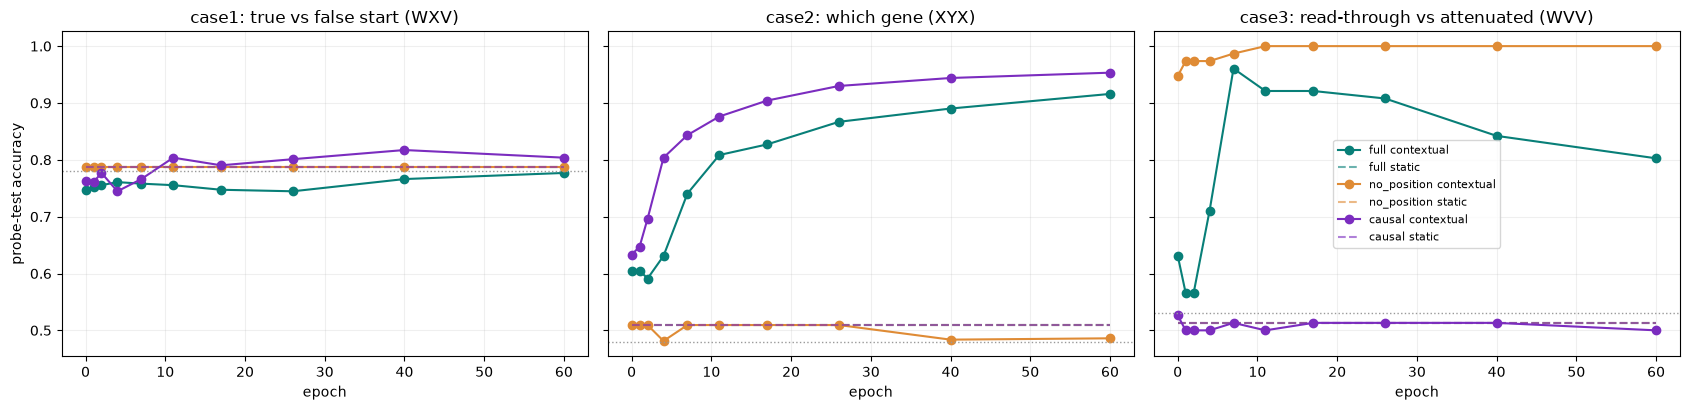

/tmp/ipykernel_50465/2192672073.py:19: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  final_table["majority (spec)"] = pd.Series(MAJORITY)


full            no_position            causal             \
      static contextual      static contextual static contextual   
case1  0.788      0.777       0.788      0.788  0.788      0.804   
case2  0.509      0.916       0.509      0.486  0.509      0.953   
case3  0.513      0.803       0.513      1.000  0.513      0.500   

      majority (spec)  
                       
case1            0.78  
case2            0.48  
case3            0.53

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
colours = {"full": "#087f78", "no_position": "#df8b35", "causal": "#7b2cbf"}
for ax, case in zip(axes, CASES):
    for name in CONFIGS:
        c = curves[name][case]
        ax.plot(EPOCHS, [r["contextual"] for r in c], marker="o", color=colours[name], label=f"{name} contextual")
        ax.plot(EPOCHS, [r["static"] for r in c], "--", color=colours[name], alpha=0.6, label=f"{name} static")
    ax.axhline(MAJORITY[case], color="#999", lw=1, ls=":")
    ax.set_title(f"{case}: {CASES[case]['title']} ({CASES[case]['token']})")
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("probe-test accuracy")
axes[-1].legend(fontsize=8)
fig.tight_layout()
plt.show()

final_table = pd.DataFrame({(name, kind): {case: curves[name][case][-1][kind] for case in CASES}
                            for name in CONFIGS for kind in ("static", "contextual")})
final_table["majority (spec)"] = pd.Series(MAJORITY)
final_table.round(3)

## 4. Case 1 in detail: does WXV look at its RBS, and does breaking the RBS move it?

**C2(a).** For every true start, the fraction of the start codon's attention that lands on its own two RBS codons,
averaged over true starts — for every layer and head of the `full` model. With about 120 tokens per transcript,
attention spread evenly would put about 0.02 there.

**C2(b).** Take each true start in the probe-test half that the probe classifies correctly, mutate the nearer RBS
codon `WXX` → `XXX` (one base), run the encoder again and ask the same probe. How often does it now say "false
start"?

In [6]:
def rbs_positions(tr, start):
    # Positions (in ids) of the RBS codons of the gene whose start is at `start`.
    gene = tr["gene"][start - 1]
    return [i + 1 for i, (r, g) in enumerate(zip(tr["region"], tr["gene"])) if r == "rbs" and g == gene]


W_full, config_full = encoders["full"]["arrays"][-1], encoders["full"]["config"]
true_starts = [o for o in occurrences["case1"] if o[3] == "true_start"]
mass = np.zeros((config_full["n_layers"], config_full["n_heads"]))
for t, pos, _, _ in true_starts:
    _, attentions = encoder_forward(W_full, config_full, transcripts[t]["ids"])
    rbs = rbs_positions(transcripts[t], pos)
    for layer, weights in enumerate(attentions):
        mass[layer] += weights[:, pos, rbs].sum(axis=-1)
mass /= len(true_starts)
print("Mean attention from a true-start WXV onto its two RBS codons (rows: layer, columns: head):")
print(np.round(mass, 3))
c2a = float(mass.max())


def flip_rate(name):
    W, config, probe = encoders[name]["arrays"][-1], encoders[name]["config"], final_probes[(name, "case1")]
    flipped = tested = 0
    for (t, pos, label, detail), is_train in zip(occurrences["case1"], split["case1"]):
        if is_train or detail != "true_start":
            continue
        tr = transcripts[t]
        final, _ = encoder_forward(W, config, tr["ids"])
        if probe.predict(final[[pos]])[0] != "true_start":
            continue                                  # only starts the probe gets right
        ids = list(tr["ids"])
        ids[max(rbs_positions(tr, pos))] = TOKEN_ID["XXX"]      # the RBS codon nearer to the start
        mutated, _ = encoder_forward(W, config, ids)
        tested += 1
        flipped += probe.predict(mutated[[pos]])[0] == "false_start"
    return flipped / tested, tested


c2b, c2b_n = flip_rate("full")
print(f"\nBreaking the RBS flips the case-1 probe to 'false start' for {c2b:.3f} of {c2b_n} correctly classified true starts")

Mean attention from a true-start WXV onto its two RBS codons (rows: layer, columns: head):
[[0.061 0.034]
 [0.001 0.045]]



Breaking the RBS flips the case-1 probe to 'false start' for 0.011 of 278 correctly classified true starts


## 5. Verdicts

Each prediction with its pass criterion from design-spec §7, and the numbers as they came out.

In [7]:
acc = lambda name, case: curves[name][case][-1]["contextual"]
static = lambda name, case: curves[name][case][-1]["static"]
verdicts = [
    {"id": "C1", "criterion": "full: static ≤ majority + 0.02 and contextual ≥ 0.95, cases 1–3",
     "result": "; ".join(f"{c}: static {static('full', c):.3f}, contextual {acc('full', c):.3f}" for c in CASES),
     "holds": all(static("full", c) <= MAJORITY[c] + 0.02 and acc("full", c) >= 0.95 for c in CASES)},
    {"id": "C2", "criterion": "full: (a) max attention mass on RBS ≥ 0.30; (b) RBS mutation flips ≥ 80%",
     "result": f"(a) {c2a:.3f}; (b) {c2b:.3f} of {c2b_n}", "holds": c2a >= 0.30 and c2b >= 0.80},
    {"id": "C3", "criterion": "full: case 2 contextual ≥ 0.90",
     "result": f"{acc('full', 'case2'):.3f}", "holds": acc("full", "case2") >= 0.90},
    {"id": "C4", "criterion": "causal: case 3 ≤ majority + 0.05; cases 1, 2 ≥ 0.90",
     "result": f"case3 {acc('causal', 'case3'):.3f} (≤ {MAJORITY['case3'] + 0.05:.2f}); case1 {acc('causal', 'case1'):.3f}; case2 {acc('causal', 'case2'):.3f}",
     "holds": acc("causal", "case3") <= MAJORITY["case3"] + 0.05 and acc("causal", "case1") >= 0.90 and acc("causal", "case2") >= 0.90},
    {"id": "C5", "criterion": "no_position: cases 1, 2 ≤ majority + 0.10",
     "result": f"case1 {acc('no_position', 'case1'):.3f} (≤ {MAJORITY['case1'] + 0.10:.2f}); case2 {acc('no_position', 'case2'):.3f} (≤ {MAJORITY['case2'] + 0.10:.2f})",
     "holds": acc("no_position", "case1") <= MAJORITY["case1"] + 0.10 and acc("no_position", "case2") <= MAJORITY["case2"] + 0.10},
]
pd.set_option("display.max_colwidth", 140)
pd.DataFrame(verdicts).assign(holds=lambda d: d["holds"].map({True: "holds", False: "fails"}))

,id,criterion,result,holds
0,C1,"full: static ≤ majority + 0.02 and contextual ≥ 0.95, cases 1–3","case1: static 0.788, contextual 0.777; case2: static 0.509, contextual 0.916; case3: static 0.513, contextual 0.803",fails
1,C2,full: (a) max attention mass on RBS ≥ 0.30; (b) RBS mutation flips ≥ 80%,(a) 0.061; (b) 0.011 of 278,fails
2,C3,full: case 2 contextual ≥ 0.90,0.916,holds
3,C4,"causal: case 3 ≤ majority + 0.05; cases 1, 2 ≥ 0.90",case3 0.500 (≤ 0.58); case1 0.804; case2 0.953,fails
4,C5,"no_position: cases 1, 2 ≤ majority + 0.10",case1 0.788 (≤ 0.88); case2 0.486 (≤ 0.58),holds


### A descriptive check for case 3: cut the transcript after the attenuator

Not a pre-registered test, but the experiment of Lab C's mutation editor: take each `K_low` transcript of the
probe-test half, delete everything after the attenuator (making it look like a `K_high` transcript), and ask the
`full` model's case-3 probe again.

In [8]:
probe3 = final_probes[("full", "case3")]
counts = {"K_low": {}, "K_low cut after the attenuator": {}, "K_high": {}}
for t, pos, label, _ in [o for o, is_train in zip(occurrences["case3"], split["case3"]) if not is_train]:
    tr = transcripts[t]
    prediction = probe3.predict(encoder_forward(W_full, config_full, tr["ids"])[0][[pos]])[0]
    counts[tr["condition"]][prediction] = counts[tr["condition"]].get(prediction, 0) + 1
    if tr["condition"] == "K_low":
        cut = tr["ids"][: pos + 2] + [TOKEN_ID["[EOS]"]]          # … attenuator (WVV VVV), then [EOS]
        prediction = probe3.predict(encoder_forward(W_full, config_full, cut)[0][[pos]])[0]
        counts["K_low cut after the attenuator"][prediction] = counts["K_low cut after the attenuator"].get(prediction, 0) + 1
pd.DataFrame(counts).fillna(0).astype(int).T

,read_through,attenuated
K_low,29,8
K_low cut after the attenuator,8,29
K_high,7,32


## 6. Occurrence clouds

For each configuration and case, PCA on the final-snapshot vectors gives two fixed axes. Every occurrence is
projected on them — at an early snapshot and at the end — so the clouds can be watched forming (Lab C does this
live, with the same axes). Points are coloured by the ground-truth label.

> Proximity in these clouds means similar contexts, not similar meaning.

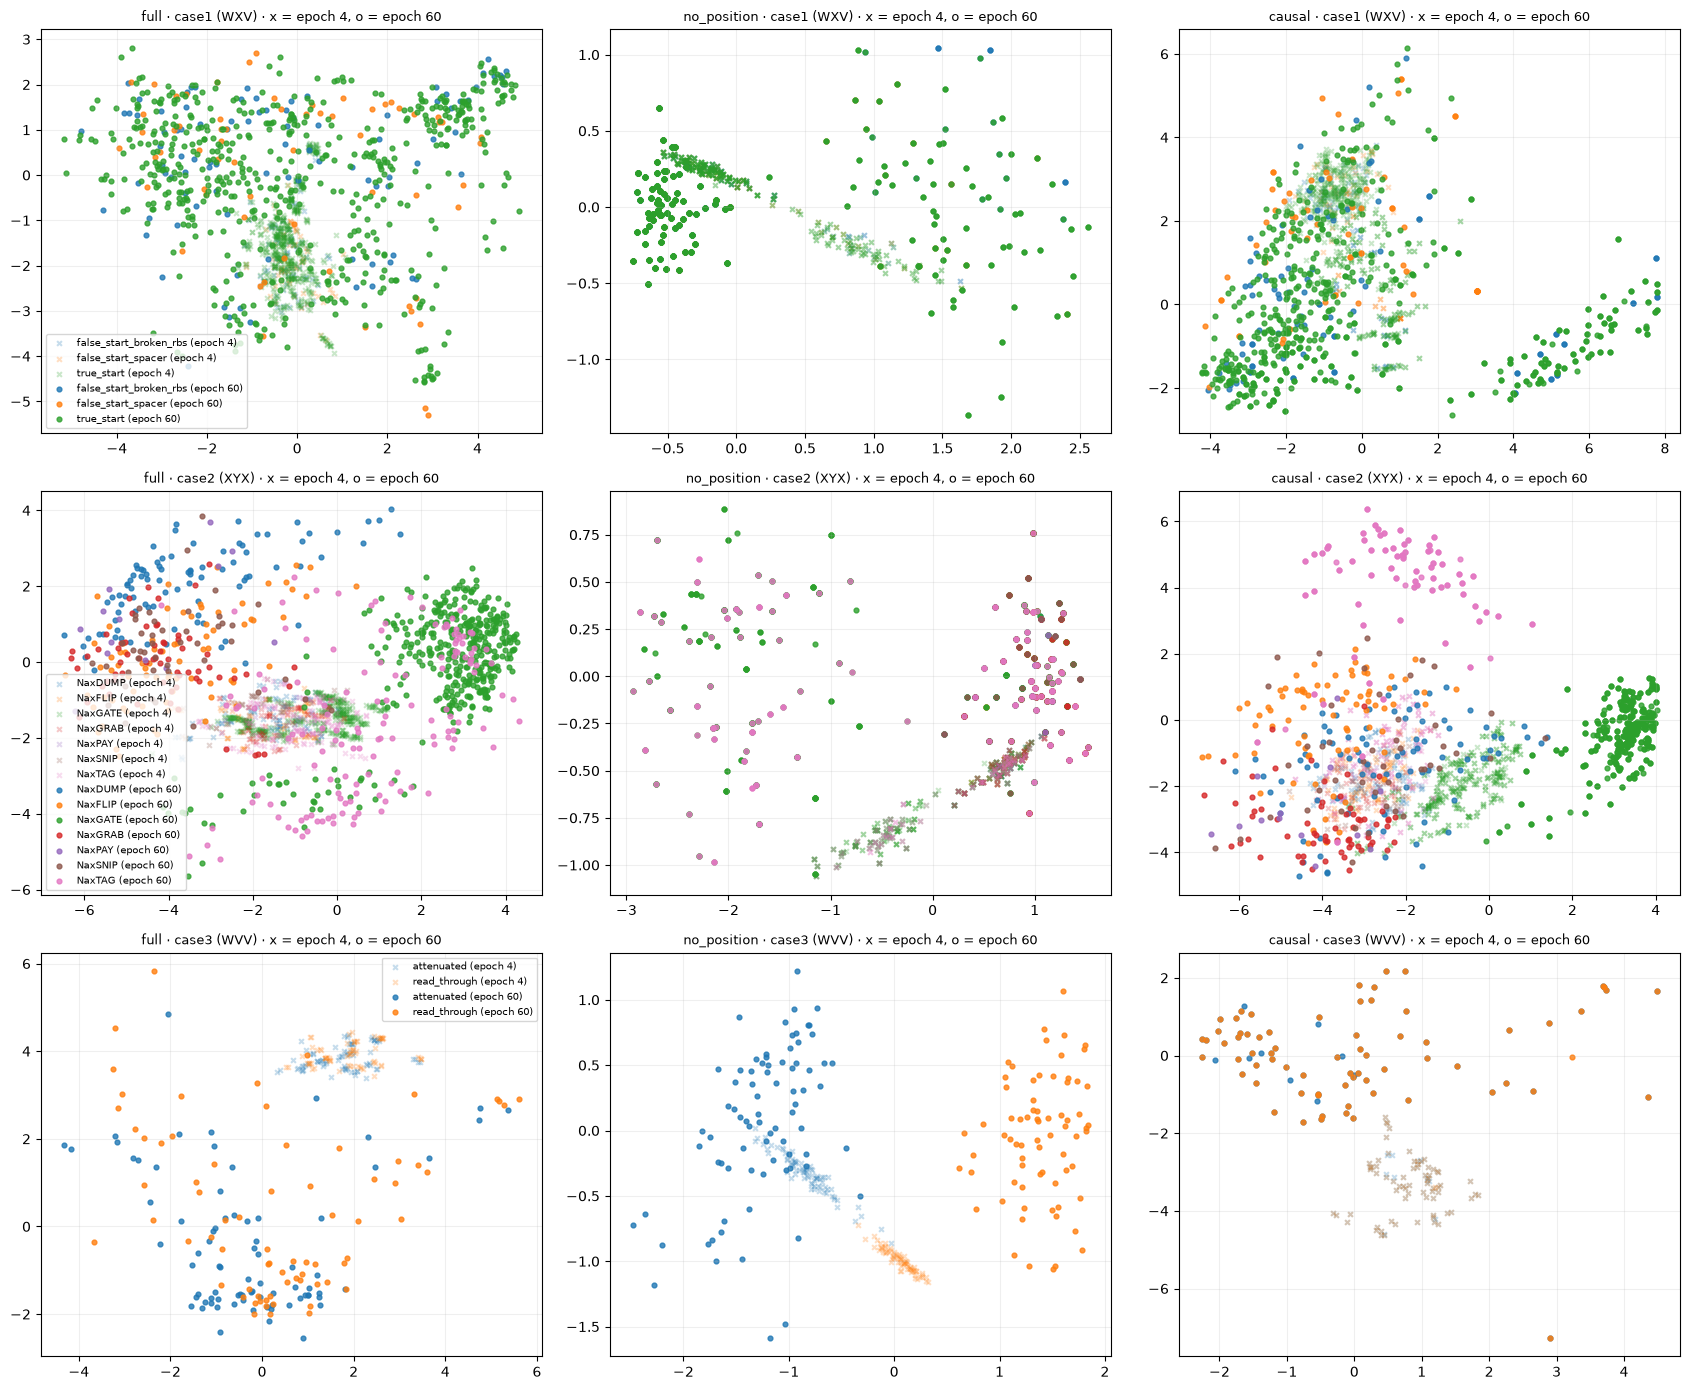

In [9]:
pca_axes = {}
for name in CONFIGS:
    for case in CASES:
        pca = PCA(n_components=2).fit(final_vectors[name][case])
        pca_axes[(name, case)] = pca

early = EPOCHS.index(4)
early_vectors = {name: occurrence_vectors(name, early) for name in CONFIGS}
fig, axes = plt.subplots(3, 3, figsize=(17, 14))
for row, case in enumerate(CASES):
    detail = np.array([o[3] for o in occurrences[case]])
    classes = sorted(set(detail))
    for col, name in enumerate(CONFIGS):
        ax, pca = axes[row, col], pca_axes[(name, case)]
        for snapshot, alpha, marker in ((early, 0.25, "x"), (len(EPOCHS) - 1, 0.8, "o")):
            xy = pca.transform((early_vectors if snapshot == early else final_vectors)[name][case])
            for k, c in enumerate(classes):
                pts = xy[detail == c]
                ax.scatter(pts[:, 0], pts[:, 1], s=12, alpha=alpha, marker=marker, color=plt.cm.tab10(k),
                           label=f"{c} (epoch {EPOCHS[snapshot]})" if col == 0 else None)
        ax.set_title(f"{name} · {case} ({CASES[case]['token']}) · x = epoch {EPOCHS[early]}, o = epoch {EPOCHS[-1]}", fontsize=9)
        ax.grid(alpha=0.2)
    axes[row, 0].legend(fontsize=7, loc="best")
fig.tight_layout()
plt.show()

## 7. Two static views side by side

The encoder's input table `tok_emb` is a static embedding too: one row per token, learned as a by-product of
masked-token training. Next to it, word2vec from notebook 03b (mixed DNA+RNA corpus, ±1, dimension 8 — the run
that contains RNA spellings). Both are drawn by PCA and coloured by codon class. This is descriptive: two
different objectives, two different static geometries.

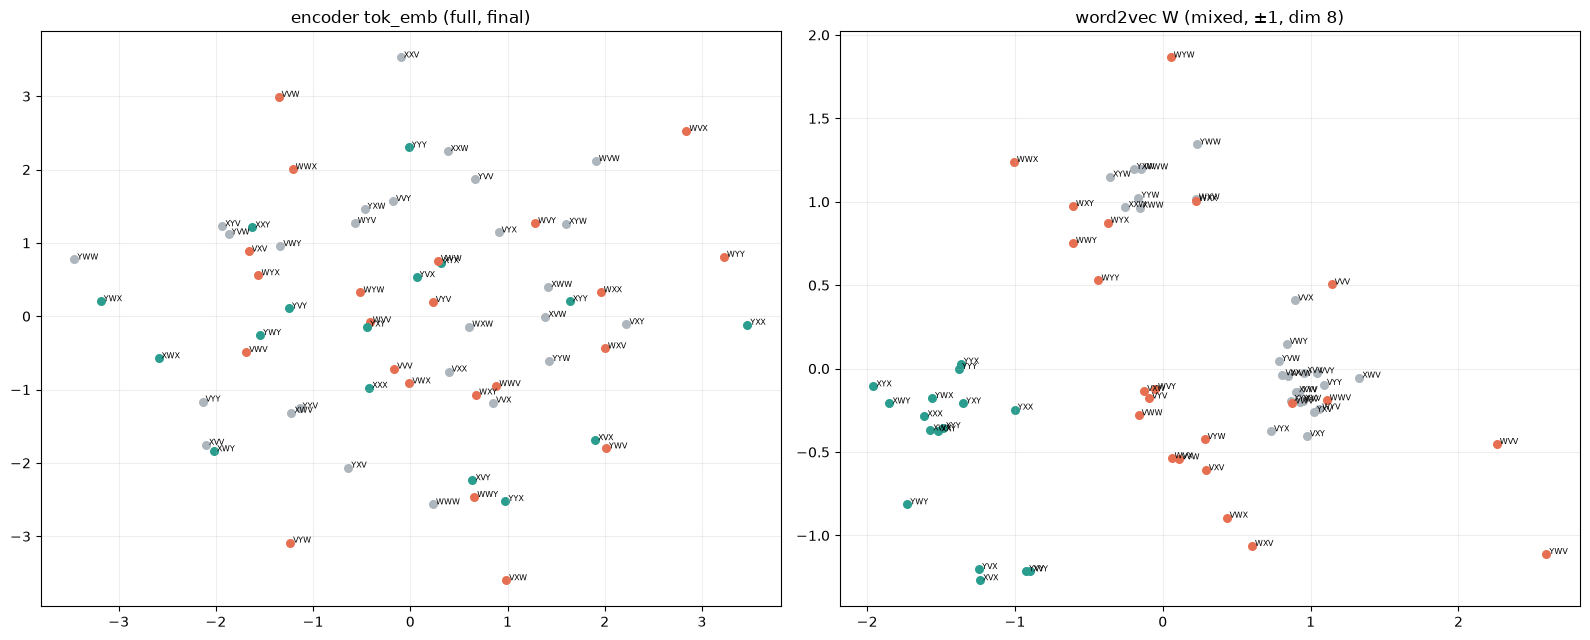

Correlation between the two cosine-similarity matrices (64 RNA codons): 0.03


In [10]:
with open(f"{WEB_DIR}/w2v-results.json") as f:
    w2v = json.load(f)
w2v_cfg = next(c for c in w2v["configs"] if c["corpus"] == "mixed" and c["half_window"] == 1 and c["dim"] == 8)
w2v_vocab = w2v["vocabularies"]["mixed"]
codons = [t for t in VOCABULARY[4:] if t in w2v_vocab]
class_colour = {"coding": "#2a9d8f", "reserved": "#e76f51", "spacer-only": "#adb5bd"}

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, (title, matrix) in zip(axes, [("encoder tok_emb (full, final)", encoders["full"]["arrays"][-1]["tok_emb.weight"][[TOKEN_ID[c] for c in codons]]),
                                      ("word2vec W (mixed, ±1, dim 8)", np.array(w2v_cfg["W"])[[w2v_vocab.index(c) for c in codons]])]):
    xy = PCA(n_components=2).fit_transform(matrix)
    for (x, y), c in zip(xy, codons):
        ax.scatter(x, y, s=30, color=class_colour[L.codon_class(c)])
        ax.text(x, y, f" {c}", fontsize=6)
    ax.set_title(title)
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

cos = lambda m: (m / np.linalg.norm(m, axis=1, keepdims=True)) @ (m / np.linalg.norm(m, axis=1, keepdims=True)).T
a = cos(encoders["full"]["arrays"][-1]["tok_emb.weight"][[TOKEN_ID[c] for c in codons]])
b = cos(np.array(w2v_cfg["W"])[[w2v_vocab.index(c) for c in codons]])
upper = np.triu_indices(len(codons), 1)
print(f"Correlation between the two cosine-similarity matrices ({len(codons)} RNA codons): {np.corrcoef(a[upper], b[upper])[0, 1]:.2f}")

### What came out (seed 42, 60-epoch encoders)

Two predictions hold and three fail. Each is stated here as it came out; nothing was changed after the
criteria were fixed.

**C3 holds — the encoder knows which gene a codon is in.**
- The case-2 probe reads the gene of `XYX` from its contextual vector with 0.916 accuracy (`full`), against a
  majority of about 0.48–0.51.
- The `causal` model does even better (0.953). The left context — the gene's marker and the body codons before
  `XYX` — is enough; the right context adds nothing here.

**C5 holds — without positions, cases 1 and 2 collapse.**
- `no_position` scores 0.788 on case 1 and 0.486 on case 2, both at the majority level.

**C1 fails — only one of the three cases approaches 100%.**
- Case 2 reaches 0.916 and case 3 reaches 0.803, but case 1 stays at 0.777, which is the majority level.
- The static half of C1 also fails on a technicality. On case 2, the static probe scores 0.509, above the
  majority + 0.02 = 0.50 fixed in the spec. A static vector is the same for every occurrence, so its probe can
  only predict one class. 0.509 is simply the share of NaxGATE in the probe-test half, which differs from the
  0.481 share in all the occurrences. This is a weakness of how the criterion was written (whole-set majority
  instead of probe-test majority), not information in the static vector. It is reported, not repaired.

**C2 fails — the encoder did not learn to check the RBS.**
- No layer or head puts more than 0.061 of the start codon's attention on its two RBS codons (the criterion
  needed 0.30).
- Breaking the RBS flips the case-1 probe for 1% of the true starts (needed 80%).
- This is the most instructive result of the notebook. Masked-codon prediction never *asks* whether a start is
  a true start. To guess a masked codon, the encoder mostly needs the gene's dialect, which it learns well
  (case 2). Whether the RBS is intact barely changes what codons come next, so nothing pushes the model to
  encode it.
- In notebook 04a the same question was the training objective, and one head learned it perfectly. **What a
  model represents depends on what it was trained to predict.**

**C4 fails — but its case-3 part holds.**
- The `causal` model's case-3 probe is at chance (0.500), as predicted: a model that looks only to the left
  cannot know what follows the attenuator.
- Case 2 survives (0.953). Case 1 does not reach 0.90 (0.804), for the same reason as in C2: no configuration
  learned case 1.

**A surprise: `no_position` solves case 3 perfectly (1.000).**
- The prediction assumed that case 3 is about *order* (what comes right after the attenuator). Without
  positions the model cannot see order, but it can see *which tokens are in the transcript at all*.
- A read-through transcript contains five more genes, with their markers and dialects; an attenuated one does
  not. The attenuator's vector is a weighted average over the whole transcript, so it reflects that
  difference.
- The cue the spec had in mind (bidirectional attention to the right) and the cue the model found
  (composition of the whole transcript) are different. The causal model's failure shows the right-hand side
  matters; the no-position model's success shows that position is not needed to use it.

**Static view.** The encoder's input table and the word2vec vectors are two static embeddings trained on
different objectives. Their cosine-similarity structures are almost unrelated (correlation 0.03).

**Caveats.**
- The `full` encoder was still improving at epoch 60 (test loss 2.84 → 2.75 between epochs 40 and 60). Longer
  training might change case 1. The number of epochs was fixed before this notebook ran and has not been
  changed since.
- The case-3 probe is scored on only 76 occurrences, so its accuracy moves in steps of about 1.3%.

**Cutting a transcript after its attenuator** (the descriptive check above, also a preset of Lab C's mutation
editor) moves most `K_low` transcripts from "read-through" to "attenuated" in the eyes of the `full` model's
case-3 probe. The information it uses really does come from what follows the attenuator.

## 8. Export for Lab C

- Each `encoder-<config>.json` gains a `probes` block: the probe curves, and the final probe's weights so the
  browser can score an edited token live.
- `contextual-sample.json` holds the 150 test transcripts with their labels, the occurrences of each target, the
  PCA axes per configuration and case, a few reference projections (to check the browser), and the verdicts.

In [11]:
def probe_block(name, case):
    probe = final_probes[(name, case)]
    return {"target": CASES[case]["token"], "label": CASES[case]["label"], "majority": MAJORITY[case],
            "classes": [str(c) for c in probe.classes_], "curve": curves[name][case],
            "final": {"coef": probe.coef_.tolist(), "intercept": probe.intercept_.tolist()}}


sizes = {}
for name in CONFIGS:
    path = f"{WEB_DIR}/encoder-{name}.json"
    with open(path) as f:
        payload = json.load(f)
    payload["probes"] = {case: probe_block(name, case) for case in CASES}
    with open(path, "w", encoding="utf-8") as f:
        json.dump(payload, f, separators=(",", ":"))
    sizes[path] = os.path.getsize(path)

sample = {
    "metadata": {
        "produced_by": NOTEBOOK, "function": "run_probe",
        "source": "\n\n".join(inspect.getsource(f) for f in (encoder_forward, find_occurrences, run_probe, occurrence_vectors, flip_rate)),
        "seed": SEED, "params": {"cases": CASES, "majority": MAJORITY, "probe": "LogisticRegression(C=1.0)",
                                 "probe_split": "50/50 by test genome"},
        "generator_version": L.GENERATOR_VERSION,
        "created": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    },
    "probe_train_genomes": sorted(probe_train_genomes),
    "transcripts": transcripts,
    "targets": {case: {**CASES[case], "classes": sorted({o[2] for o in occ}), "details": sorted({str(o[3]) for o in occ}),
                       "occurrences": [[t, pos, label, detail] for t, pos, label, detail in occ]}
                for case, occ in occurrences.items()},
    "pca": {name: {case: {"mean": pca_axes[(name, case)].mean_.tolist(), "components": pca_axes[(name, case)].components_.tolist(),
                          "explained": pca_axes[(name, case)].explained_variance_ratio_.tolist(),
                          "reference": pca_axes[(name, case)].transform(final_vectors[name][case][:5]).tolist()}
                   for case in CASES} for name in CONFIGS},
    "verdicts": verdicts,
}
path = f"{WEB_DIR}/contextual-sample.json"
with open(path, "w", encoding="utf-8") as f:
    json.dump(sample, f, separators=(",", ":"))
sizes[path] = os.path.getsize(path)
for p, size in sizes.items():
    print(f"{p:40} {size / 1e6:5.2f} MB")
total = sum(os.path.getsize(f"{WEB_DIR}/{f}") for f in os.listdir(WEB_DIR) if f.endswith(".json"))
print(f"{'all data/web JSON':40} {total / 1e6:5.2f} MB")
assert max(sizes.values()) <= 5e6 and total <= 20e6, "size budget exceeded"

../data/web/encoder-full.json             2.83 MB
../data/web/encoder-no_position.json      2.06 MB
../data/web/encoder-causal.json           2.83 MB
../data/web/contextual-sample.json        0.77 MB
all data/web JSON                        15.18 MB
